# Unit cost under tariff and subsidy shocks

Compare the sector-level change in unit cost against the baseline for the same year. The detail figures show each importing region and policy group. The summary figures compare the low, central and high elasticity calibrations.

Set the options below and use **Run All**. From inside the ENTICE project, the notebook finds the shock folder used by `shock_horizon`. For a standalone run, set `SHOCK_DIR` to the folder containing the exported CSVs. Figures are written under `SHOCK_DIR/graphs_horizon/`.

In [11]:
from pathlib import Path
import importlib.util
import re

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd

BASE = "EXIOBASE"             # For example, "GTAP"
CONTENT = "dir"               # "dir" or "tot", as in the export filename
CASE = "model1_caseC"         # Model and substitution case in the CSV
YEARS = [2050]                # Or [2030, 2040, 2050], one figure per year
GROUPS = [1, 2, 3, 4, 5]      # All available groups 1–5, or an explicit list such as [1, 3]
REGIONS = None                # None for all importing regions, or e.g. ["China", "EU27"] for individual regions
SCENARIO_PALETTE = "bright"  # "bright" or "original"
EXPORT_HEATMAPS = False       # Export the central and sign maps too
EXPORT_BOXPLOTS = False       # Export individual and combined boxplot figures
EXPORT_SECTOR_AGGREGATES = True  # Export a comparison of C, Non-manufacturing and All sectors
SHOCK_DIR = None  # Use the configured run, or set a Path to an AllCases CSV folder.

## Read sector totals

The lookup reproduces `SECTOR_NAMES` from the shock notebook. A sector label becomes a project code in memory. `C10_C12`, for example, covers food, beverages and tobacco. `C` and `H` are the aggregate shocks exported by the model. The project’s `H` includes `H53+J`. Bilateral contributions labelled `sector | supplier` are excluded because the sector total is already available.

In [12]:
SECTOR_NAMES = {
    "A": "Agriculture, forestry and fishing",
    "B": "Mining and quarrying",
    "C": "Manufacturing",
    "NONMANUF": "Non-manufacturing",
    "C10_C12": "Food, beverages and tobacco",
    "C13_C15": "Textiles, wearing apparel and leather products",
    "C16_C18": "Wood, paper and printing products",
    "C19": "Coke and refined petroleum products",
    "C20+C21": "Chemicals and pharmaceuticals",
    "C22": "Rubber and plastic products",
    "C23": "Other non-metallic mineral products",
    "C24": "Basic metals",
    "C25": "Fabricated metal products",
    "C26": "Computer, electronic and optical products",
    "C27": "Electrical equipment",
    "C28": "Machinery and equipment n.e.c.",
    "C29": "Motor vehicles, trailers and semi-trailers",
    "C30": "Other transport equipment",
    "C31_C33": "Furniture, other manufacturing, machinery repair and installation",
    "D": "Electricity, gas, steam and air conditioning supply",
    "E": "Water supply, sewerage, waste management and remediation",
    "F": "Construction",
    "G": "Wholesale and retail trade, motor vehicle repair",
    "H": "Transportation, storage, information and communication services",
    "H49": "Land transport and transport via pipelines",
    "H50": "Water transport",
    "H51": "Air transport",
    "H52": "Warehousing and support activities for transportation",
    "H53+J": "Postal, courier, information and communication services",
    "I": "Accommodation and food service activities",
    "K": "Financial and insurance activities",
    "L": "Real estate activities",
    "M+N": "Professional, scientific, technical, administrative and support services",
    "O+U": "Public administration, defence, social security and extraterritorial organisations",
    "P": "Education",
    "Q": "Human health and social work activities",
    "R+S+T": "Arts, entertainment, recreation, other services and household activities",
    "ALLSECT": "All sectors",
}
CODE_BY_NAME = {name: code for code, name in SECTOR_NAMES.items()}

In [13]:
CALIBRATIONS = ("low", "central", "high")
REGION_MARKERS = {
    "USA": "o", "EU27": "s", "China": "D", "RestOECD": "^",
    "RestBRICS": "P", "RestAsia": "X", "RoW": "v",
}
SCENARIO_PALETTES = {
    "original": {1: "#0072B2", 2: "#D55E00", 3: "#00845E", 4: "#9B5592", 5: "#926600"},
    "bright": {1: "#008DFF", 2: "#FF7800", 3: "#00C77A", 4: "#BE41FF", 5: "#E7B500"},
}
SCENARIO_COLOURS = SCENARIO_PALETTES[SCENARIO_PALETTE]


def project_shock_dir():
    for parent in (Path.cwd(), *Path.cwd().parents):
        settings_path = parent / "code" / "project_settings.py"
        if settings_path.is_file():
            spec = importlib.util.spec_from_file_location("entice_plot_settings", settings_path)
            settings = importlib.util.module_from_spec(spec)
            spec.loader.exec_module(settings)
            return Path(settings.RESULTS_DIR) / "shock_tfp"
    raise FileNotFoundError("Set SHOCK_DIR to the folder with the AllCases CSVs or open the notebook inside ENTICE.")


def select_files(folder, groups):
    if not folder.is_dir():
        raise FileNotFoundError(f"Shock directory does not exist: {folder}")
    prefix = f"ENTICE_T34_{BASE}-{CONTENT}_AllCases_TariffsAndSub_grp"
    pattern = re.compile(re.escape(prefix) + r"([1-5])_(low|central|high)\.csv", re.IGNORECASE)
    files = {}
    for path in sorted(folder.iterdir()):
        match = pattern.fullmatch(path.name)
        if match and path.is_file():
            key = (int(match[1]), match[2].lower())
            if key in files:
                raise ValueError(f"Two exports match {key} in {folder}")
            files[key] = path
    available = sorted({g for g, _ in files})
    if not available:
        raise FileNotFoundError(f"No files matching {prefix}<1-5>_<low|central|high>.csv in {folder}")
    selected = available if groups is None else sorted(set(groups))
    if not selected or not set(selected) <= set(SCENARIO_COLOURS):
        raise ValueError("GROUPS must select at least one policy group between 1 and 5.")
    missing = [f"{prefix}{g}_{c}.csv" for g in selected for c in CALIBRATIONS if (g, c) not in files]
    if missing:
        raise FileNotFoundError("Missing calibration exports:\n" + "\n".join(missing))
    return selected, files


def read_totals(path, group, calibration):
    df = pd.read_csv(path, sep=";", decimal=",", encoding="utf-8-sig")
    region_column = "Region (importer)" if "Region (importer)" in df else "Region"
    required = ["Model", "Case", region_column, "Variable", "Unit", *map(str, YEARS)]
    missing = [c for c in required if c not in df]
    if missing:
        raise ValueError(f"{path.name}: missing columns {missing}")
    available_cases = df["Case"].dropna().unique().tolist()
    totals = df.loc[df["Case"].eq(CASE) & ~df["Variable"].str.contains("|", regex=False, na=False)].copy()
    if totals.empty:
        raise ValueError(f"{path.name}: no sector totals for {CASE!r}. Cases in this file: {available_cases}")
    if not totals["Unit"].eq("%").all() or totals[[region_column, "Variable", "Model"]].isna().any().any():
        raise ValueError(f"{path.name}: expected percentage units and nonempty model, region and sector fields.")
    labels = totals["Variable"].str.strip()
    codes = labels.map(CODE_BY_NAME).fillna(labels)
    bad = sorted(set(codes) - set(SECTOR_NAMES))
    if bad:
        raise ValueError(f"{path.name}: add these labels or codes to SECTOR_NAMES: {bad}")
    totals["sector_code"] = codes
    totals = totals.rename(columns={region_column: "region", "Model": "model_name"})
    if totals.duplicated(["region", "sector_code"]).any():
        raise ValueError(f"{path.name}: duplicate sector totals for the selected case. Check the Model column.")
    data = totals.melt(id_vars=["model_name", "region", "sector_code"], value_vars=list(map(str, YEARS)),
                       var_name="year", value_name="change_pct")
    data["year"] = data["year"].astype(int)
    # Decimal commas have already been read. Reject malformed values and keep missing values missing.
    data["change_pct"] = pd.to_numeric(data["change_pct"], errors="raise")
    if np.isinf(data["change_pct"]).any():
        raise ValueError(f"{path.name}: infinite cost change.")
    return data.assign(group=group, calibration=calibration)


if not YEARS or any(not isinstance(y, int) for y in YEARS) or len(set(YEARS)) != len(YEARS):
    raise ValueError("YEARS must be a nonempty list of distinct integer years.")
folder = Path(SHOCK_DIR).expanduser() if SHOCK_DIR is not None else project_shock_dir()
group_ids, input_files = select_files(folder, GROUPS)
data = pd.concat([read_totals(input_files[g, c], g, c) for g in group_ids for c in CALIBRATIONS],
                 ignore_index=True)
if data["model_name"].nunique() != 1:
    raise ValueError("Selected files refer to different simulation models.")
observed = set(data["region"])
region_ids = [r for r in REGION_MARKERS if r in observed] if REGIONS is None else list(dict.fromkeys(REGIONS))
unknown = (observed if REGIONS is None else set(region_ids)) - set(REGION_MARKERS)
if unknown:
    raise ValueError(f"Add markers to REGION_MARKERS for these importing regions: {sorted(unknown)}")
if not region_ids or set(region_ids) - observed:
    raise ValueError(f"REGIONS must select existing importers from {sorted(observed)}")
data = data.loc[data["region"].isin(region_ids)].copy()
print("Policy groups:", group_ids, "| Importers:", ", ".join(region_ids), "| Years:", YEARS)
print("Folder:", folder, "| Case:", CASE, "| Calibration triplets:", len(group_ids))

Policy groups: [1, 2, 3, 4, 5] | Importers: USA, EU27, China, RestOECD, RestBRICS, RestAsia, RoW | Years: [2050]
Folder: D:\ENTICE\runs\SRDQ (c,s)\choc_tfp | Case: model1_caseC | Calibration triplets: 5


## Plot and save

The Manufacturing figures show C and its subsectors. The All sectors figures include aggregates C and H alongside the other non-manufacturing sectors. With `EXPORT_SECTOR_AGGREGATES = True`, the compact figure compares All sectors, Manufacturing and Non-manufacturing, in that order. The Low, Central and High panels sit side by side with a shared vertical percentage scale.

For each year and sector family, export one scatter plot per calibration and one figure with all three calibrations in separate panels. Color identifies the scenario and marker shape identifies the importing region. Semi-transparent markers and horizontal offsets help distinguish nearby estimates within each sector.

The zero line marks the baseline. Alternating white and light gray bands delineate sectors. Darker gray bands and bold codes identify the exported aggregates. All figures within a sector family use the same percentage scale across years. The notebook displays the first figure and saves all figures as PNGs.

With `EXPORT_HEATMAPS = True`, the central heatmaps use one symmetric color scale across all selected years and sectors. Sign maps compare the three calibrations using SIGN_TOLERANCE_PP in percentage points. Gray cells indicate missing inputs.

With `EXPORT_BOXPLOTS = True`, export a figure per calibration and a combined figure for each family and year. Each box summarizes the available region-group results for one sector and calibration with equal weight. Boxes cover the middle 50%, lines mark medians, and whiskers extend to observed values within 1.5 times the interquartile range. Boxes have transparent interiors. All observations, including those beyond the whiskers, are shown as points colored by policy group and shaped by importing region.

In [14]:
COMPARISON_SECTORS = ("ALLSECT", "C", "NONMANUF")
AGGREGATE_SECTORS = {*COMPARISON_SECTORS, "H"}
SECTOR_DISPLAY_LABELS = {"C": "Manufacturing", "NONMANUF": "Non-manufacturing", "ALLSECT": "All sectors"}
COST_AXIS_LABEL = "Change in unit cost (%, w.r.t. baseline)"


def percent_limits(values):
    finite = values.dropna()
    if finite.empty:
        raise ValueError("No finite values in this selection.")
    low, high = min(0.0, finite.min()), max(0.0, finite.max())
    pad = 0.07 * (high - low) if high > low else 0.1
    return low - pad, high + pad


def figure_title(family, year):
    scenario = "Tariff shock with compensation"
    if re.fullmatch(r"model[0-9]+_caseB", CASE):
        scenario += " (domestic substitution)"
    elif re.fullmatch(r"model[0-9]+_caseA", CASE):
        scenario += " (no domestic substitution)"
    elif re.fullmatch(r"model[0-9]+_caseC", CASE):
        scenario += " (domestic production follows NEMESIS)"
    return f"{scenario} | {family} | {year}"


def format_sector_axis(ax, sectors, limits):
    # Shared sector bands for scatter plots and boxplots.
    positions = np.arange(len(sectors))
    ax.set_facecolor("white")
    for position, sector in zip(positions, sectors):
        if sector in AGGREGATE_SECTORS:
            shade = "#d8dde1"
        elif position % 2:
            shade = "#f1f3f5"
        else:
            continue
        ax.axvspan(position - 0.5, position + 0.5, facecolor=shade, lw=0, zorder=0)
    labels = sectors
    ax.set_xticks(positions, labels=labels, rotation=45, ha="right", rotation_mode="anchor")
    for label, sector in zip(ax.get_xticklabels(), sectors):
        if sector in AGGREGATE_SECTORS:
            label.set_weight("bold")
    ax.set(xlim=(-0.5, len(sectors) - 0.5), ylim=limits)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.grid(axis="y", color="#e0e5e7", lw=0.65, zorder=1)
    ax.axhline(0, color="#56646b", lw=1, zorder=2)
    ax.tick_params(axis="both", length=0, labelsize=9, pad=4)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#cad1d3")


def plot_calibrations(frame, sectors, family, year, calibrations, limits, *, boxplots=False):
    combined = len(calibrations) > 1
    detail = "Low, central and high calibrations" if combined else f"{calibrations[0].title()} calibration"
    if boxplots:
        detail += " | Distribution across regions and policy groups"
    title = figure_title(family, year)
    compact = family == "Sector aggregates"
    if compact:
        size = (9, 4.7)
        scenario, heading = title.split(" | ", 1)
        title = scenario + chr(10) + heading
    else:
        size = (max(12, 2 + 0.73 * len(sectors)), 2.0 + 2.7 * len(calibrations))
    fig = plt.figure(figsize=size, layout="constrained")
    if not compact:
        title += chr(10) + detail
    fig.suptitle(title, fontsize=12 if compact else 15, weight="bold")
    if compact:
        grid = fig.add_gridspec(3, len(calibrations), height_ratios=[0.27, 0.27, 3.1])
    else:
        grid = fig.add_gridspec(len(calibrations) + 2, 1,
                               height_ratios=[0.34, 0.34] + [2.2] * len(calibrations))
    fig.supylabel(COST_AXIS_LABEL, fontsize=10 if compact else 11)
    if compact and "ALLSECT" in sectors:
        fig.supxlabel("* All sectors is weighted by sector production.", fontsize=6)

    policy_handles = [
        Line2D([], [], marker="o", linestyle="none", color=SCENARIO_COLOURS[group],
               markersize=7, label=f"Scenario {group}")
        for group in group_ids
    ]
    region_handles = [
        Line2D([], [], marker=REGION_MARKERS[region], linestyle="none",
               color="#364954", markersize=7, label=region)
        for region in region_ids
    ]
    for row, handles in enumerate((policy_handles, region_handles)):
        header = fig.add_subplot(grid[row, :])
        header.set_axis_off()
        header.legend(handles=handles, loc="center", ncol=len(handles), frameon=False,
                      fontsize=8 if compact else 9, columnspacing=1.2 if compact else 2)

    positions = np.arange(len(sectors))
    series = [(region, group) for region in region_ids for group in group_ids]
    offsets = np.linspace(-0.36, 0.36, len(series)) if len(series) > 1 else [0.0]
    indexed = frame.set_index(["calibration", "region", "group", "sector_code"])["change_pct"]
    for index, calibration in enumerate(calibrations):
        if compact:
            ax = fig.add_subplot(grid[2, index])
            ax.set_facecolor("white")
            for position, sector in zip(positions, sectors):
                shade = {"ALLSECT": "#d8dde1", "C": "white", "NONMANUF": "#f1f3f5"}[sector]
                ax.axvspan(position - 0.5, position + 0.5, facecolor=shade, lw=0, zorder=0)
            labels = dict(SECTOR_DISPLAY_LABELS, ALLSECT="All sectors*",
                          NONMANUF="Non-" + chr(10) + "manufacturing")
            tick_labels = [labels[s] for s in sectors]
            ax.set_xticks(positions, labels=tick_labels, rotation=0, ha="center")
            ax.set(xlim=(-0.5, len(sectors) - 0.5), ylim=limits)
            ax.tick_params(axis="both", length=0, labelsize=9, labelleft=index == 0)
            ax.tick_params(axis="x", labelsize=8)
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
            ax.grid(axis="y", color="#dce2e5", lw=0.6, zorder=1)
            ax.axhline(0, color="#77838b", lw=0.9, zorder=2)
            ax.spines[["top", "right", "left"]].set_visible(False)
            ax.spines["bottom"].set_color("#cad1d3")
        else:
            ax = fig.add_subplot(grid[index + 2])
            format_sector_axis(ax, sectors, limits)
            if boxplots:
                selected = frame.loc[frame["calibration"].eq(calibration)]
                draw_sector_boxes(ax, selected, sectors)
        if combined:
            caption = calibration.title() if compact else f"{calibration.title()} calibration"
            ax.set_title(caption, fontsize=11, weight="bold")
        for (region, group), offset in zip(series, offsets):
            keys = [(calibration, region, group, sector) for sector in sectors]
            values = indexed.reindex(keys).to_numpy(dtype=float)
            ax.scatter(positions + offset, values, s=24 if compact else 32 if combined else 44,
                       marker=REGION_MARKERS[region], color=SCENARIO_COLOURS[group],
                       alpha=0.62, edgecolors="white", linewidths=0.4, zorder=3)
    return fig


def draw_sector_boxes(ax, frame, sectors):
    samples = frame.dropna(subset=["change_pct"]).groupby("sector_code")["change_pct"]
    by_sector = {sector: values.to_numpy() for sector, values in samples}
    positions = [i for i, sector in enumerate(sectors) if sector in by_sector]
    if positions:
        ax.boxplot([by_sector[sectors[i]] for i in positions], positions=positions,
                   manage_ticks=False, widths=0.76, patch_artist=True, showfliers=False,
                   boxprops={"facecolor": "none", "edgecolor": "#415158"},
                   medianprops={"color": "#182830", "linewidth": 1.5},
                   zorder=2.5)


SIGN_TOLERANCE_PP = 0.01


def plot_heatmap(frame, sectors, family, year, view, central_limit):
    from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, ListedColormap, TwoSlopeNorm
    from matplotlib.patches import Patch

    central = view == "central"
    missing_color = "#d5d8dc"
    palette = [
        ("#2166ac", "Decrease in all three"),
        ("#ffffff", "Within tolerance in all three"),
        ("#b35806", "Increase in all three"),
        ("#762a83", "Changes sign"),
        ("#e9c778", "Near zero in some calibrations"),
    ]
    if central:
        cmap = LinearSegmentedColormap.from_list("cost_change", ["#2166ac", "#ffffff", "#b35806"], N=257)
        norm = TwoSlopeNorm(vmin=-central_limit, vcenter=0, vmax=central_limit)
        heading = "Central calibration"
    else:
        cmap = ListedColormap([color for color, _ in palette])
        norm = BoundaryNorm(np.arange(len(palette) + 1) - 0.5, cmap.N)
        heading = f"Sign across low, central and high | Tolerance: +/-{SIGN_TOLERANCE_PP:g} pp"
    cmap.set_bad(missing_color)

    columns = min(2, len(group_ids))
    rows = (len(group_ids) + columns - 1) // columns
    width = max(7.5, 1.8 + 0.37 * len(sectors))
    height = max(2.4, 1.05 + 0.27 * len(region_ids))
    fig = plt.figure(figsize=(columns * width, 2 + rows * height), layout="constrained")
    grid = fig.add_gridspec(rows + 1, columns, height_ratios=[0.8] + [height] * rows)
    title = figure_title(family, year)
    fig.suptitle(title + chr(10) + heading, fontsize=15, weight="bold")
    header = fig.add_subplot(grid[0, :])
    header.set_axis_off()
    missing = Patch(facecolor=missing_color, label="Missing estimate")
    if central:
        bar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=header,
                           location="bottom", fraction=0.27, shrink=0.58, pad=0)
        bar.set_label(COST_AXIS_LABEL)
        header.legend(handles=[missing], loc="center", frameon=False, fontsize=9)
    else:
        handles = [Patch(facecolor=color, edgecolor="#8d9296", label=label)
                   for color, label in palette]
        header.legend(handles=[*handles, missing], loc="center", frameon=False,
                      ncol=2 if columns == 1 else 3, fontsize=9)

    indexed = frame.set_index(["group", "region", "sector_code", "calibration"])["change_pct"]
    for index, group in enumerate(group_ids):
        row, column = divmod(index, columns)
        ax = fig.add_subplot(grid[row + 1, column])
        keys = [(group, region, sector, calibration)
                for region in region_ids for sector in sectors for calibration in CALIBRATIONS]
        values = indexed.reindex(keys).to_numpy(dtype=float).reshape(-1, len(CALIBRATIONS))
        cells = values[:, CALIBRATIONS.index("central")] if central else classify_signs(values)
        ax.imshow(cells.reshape(len(region_ids), len(sectors)), norm=norm, cmap=cmap,
                  aspect="auto", interpolation="none")
        ax.set_title(f"Scenario {group}", fontsize=11, weight="bold")
        labels = sectors
        ax.set_xticks(np.arange(len(sectors)), labels=labels, rotation=45, ha="right")
        ax.set_yticks(np.arange(len(region_ids)), labels=region_ids)
        ax.tick_params(axis="both", which="both", length=0, labelsize=9)
        ax.set_xticks(np.arange(len(sectors) + 1) - 0.5, minor=True)
        ax.set_yticks(np.arange(len(region_ids) + 1) - 0.5, minor=True)
        ax.grid(which="minor", color="#e3e5e7", linewidth=0.45)
        ax.spines[:].set_visible(False)
        for label, sector in zip(ax.get_xticklabels(), sectors):
            if sector in AGGREGATE_SECTORS:
                label.set_weight("bold")
                label.set_bbox(dict(facecolor="#e2e5e7", edgecolor="none", pad=1.5))
    return fig


def classify_signs(values):
    positive = (values > SIGN_TOLERANCE_PP).sum(axis=1)
    negative = (values < -SIGN_TOLERANCE_PP).sum(axis=1)
    count = len(CALIBRATIONS)
    return np.select(
        [~np.isfinite(values).all(axis=1), negative == count, positive + negative == 0,
         positive == count, (positive > 0) & (negative > 0)],
        [np.nan, 0, 1, 2, 3], default=4,
    )

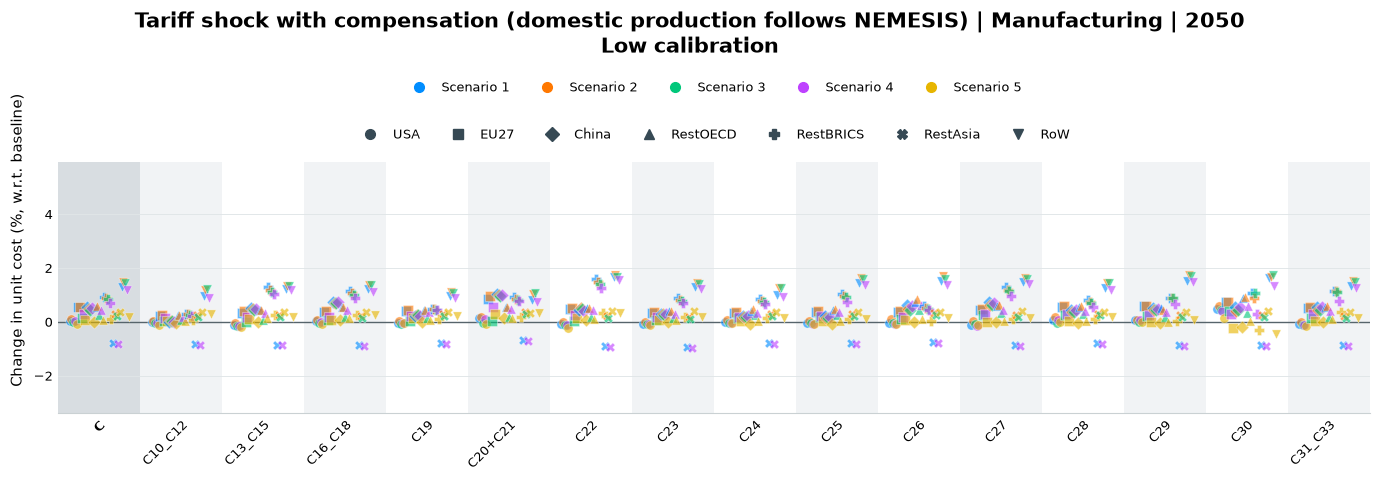

9 PNG figure(s) saved in D:\ENTICE\runs\SRDQ (c,s)\choc_tfp\graphs_horizon\EXIOBASE\dir\model1_caseC\groups_1-2-3-4-5\regions_USA-EU27-China-RestOECD-RestBRICS-RestAsia-RoW


In [15]:
# Keep selections and the scenario identifier in the output paths.
selection = "groups_" + "-".join(map(str, group_ids))
region_set = "regions_" + "-".join(region_ids)
output_dir = folder / "graphs_horizon" / BASE / CONTENT / CASE / selection / region_set
output_dir.mkdir(parents=True, exist_ok=True)
available_sectors = set(data["sector_code"])
files_written = []
central_max = data.loc[data["calibration"].eq("central"), "change_pct"].abs().max()
central_limit = central_max if pd.notna(central_max) and central_max > 0 else 0.1


def save_figure(fig, family, year, view):
    name = f"{BASE}_{CONTENT}_{CASE}_{family.lower().replace(' ', '_')}_{year}_{view}.png"
    path = output_dir / name
    fig.savefig(path, dpi=190, facecolor="white")
    if not files_written:
        plt.show()
    plt.close(fig)
    files_written.append(path)


sector_families = {
    "Manufacturing": [s for s in SECTOR_NAMES if s.startswith("C")],
    "All sectors": [
        s for s in SECTOR_NAMES
        if s not in {"ALLSECT", "NONMANUF"} and (s in {"C", "H"} or not s.startswith(("C", "H")))
    ],
}
if EXPORT_SECTOR_AGGREGATES:
    if {"C", "NONMANUF"} <= available_sectors:
        sector_families["Sector aggregates"] = COMPARISON_SECTORS
    else:
        print("Skipped Sector aggregates: the selected exports must contain C and Non-manufacturing.")

for family, family_sectors in sector_families.items():
    sectors = [s for s in family_sectors if s in available_sectors]
    if not sectors:
        continue
    family_data = data.loc[data["sector_code"].isin(sectors)]
    if not family_data["change_pct"].notna().any():
        print(f"Skipped {family}: all selected values are missing.")
        continue
    limits = percent_limits(family_data["change_pct"])
    for year in YEARS:
        frame = family_data.loc[family_data["year"].eq(year)]
        present = frame["change_pct"].count()
        if present == 0:
            print(f"Skipped {family}, {year}: no estimates.")
            continue
        expected = len(sectors) * len(region_ids) * len(group_ids) * len(CALIBRATIONS)
        if present < expected:
            print(f"{family}, {year}: {expected - present} missing points.")
        if family == "Sector aggregates":
            fig = plot_calibrations(frame, sectors, family, year, CALIBRATIONS, limits)
            save_figure(fig, family, year, "summary")
            continue
        for calibration in CALIBRATIONS:
            fig = plot_calibrations(frame, sectors, family, year, (calibration,), limits)
            save_figure(fig, family, year, calibration)
        save_figure(plot_calibrations(frame, sectors, family, year, CALIBRATIONS, limits),
                    family, year, "summary")
        if EXPORT_BOXPLOTS:
            for calibration in CALIBRATIONS:
                fig = plot_calibrations(frame, sectors, family, year, (calibration,), limits, boxplots=True)
                save_figure(fig, family, year, f"{calibration}_boxplot")
            fig = plot_calibrations(frame, sectors, family, year, CALIBRATIONS, limits, boxplots=True)
            save_figure(fig, family, year, "boxplot")
        if EXPORT_HEATMAPS:
            for view in ("central", "sign"):
                fig = plot_heatmap(frame, sectors, family, year, view, central_limit)
                save_figure(fig, family, year, f"heatmap_{view}")
print(f"{len(files_written)} PNG figure(s) saved in {output_dir.resolve()}")